# 20 日涨跌幅 Top 5：首次入榜后持有到期

本 Notebook 测试一个不因后续排名变化而主动调仓的长短组合：每个观察时点计算过去 20 个有行情交易日的纯价格涨跌幅；首次进入涨幅 Top 5 的品种下一条行情记录做多一手，首次进入跌幅 Bottom 5 的品种下一条行情记录做空一手，并持有至样本结束。已经开仓的品种不会因跌出榜单而平仓，也不会重复加仓。样本结束时按最后可用价格统一估值并结算。

这里的“持有到期”是本次实验定义的持仓规则，并非有限期限的合约到期日。价格数据来自 `data/小时Buy_And_Hold/` 下的 WT8 信息明细；入选与盈亏都不使用 WT8 原策略的权益信号。

## 重要假设

- 回测起始日为 2024-01-02，需先积累 20 个有行情交易日后才可能入场；回测结束取数据共同覆盖的最后时点。
- 回看窗口两端必须为同一实际合约；跨主连换月的窗口不参与排名。排名在每个品种有新行情时更新，其他品种使用各自最近已知的价格信号。
- 每个品种最多开一手；同一品种首次入选多头或空头一侧后不再尝试反向开仓。资金 50 万；新仓须满足估算保证金可用额，否则拒绝该次首次入场。
- 为遵守“持有到期”，持仓即使后来超过可用保证金也不会被本回测强制平仓；会记录保证金缺口。真实期货账户可能触发追加保证金或强平，因此这部分是研究模拟。
- 保证金率从 WT8 明细中的权益与可用资金估算；合约乘数从成交额反推。手续费、滑点为 0。主连换月时不把换月价差记为盈亏，也未模拟实际旧合约平仓和新合约开仓。

若老师所说的“Hold”是首次排名时只选 5 个赢家和 5 个输家、之后完全不再增加新仓，请将它与这里的“每个品种首次进入 Top/Bottom 5 时进场”区分开；本 Notebook 按后者实现，并在结果中展示持仓逐步累积的影响。

In [1]:
from bisect import bisect_right
from collections import defaultdict
from csv import reader, DictWriter
from datetime import datetime
from heapq import merge
from itertools import groupby
from pathlib import Path
from statistics import median
import math
import re

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.font_manager import FontProperties

BASE_DIR = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "小时Buy_And_Hold").is_dir()), None)
if BASE_DIR is None:
    raise FileNotFoundError("找不到 data/小时Buy_And_Hold；请从项目根目录或 notebooks/ 运行。")
DATA_DIR = BASE_DIR / "data" / "小时Buy_And_Hold"
OUTPUT_DIR = BASE_DIR / "backtest_output" / "20day_evergreen_hold"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

INITIAL_CAPITAL = 500_000.0
TOP_K = 5
LOOKBACK_DAYS = 20
START_AT = "2024-01-02 09:30:00"
END_AT = None  # None 表示取数据覆盖到的最后时点
ONE_WAY_FEE_RATE = 0.0

START_DT = datetime.fromisoformat(START_AT)
print("项目目录：", BASE_DIR)
print("规则：首次涨幅 Top 5 做多；首次跌幅 Bottom 5 做空；持有至样本结束")
print("资金：", f"¥{INITIAL_CAPITAL:,.0f}", "；每品种最多一手")

项目目录： d:\HuaweiMoveData\Users\32874\Desktop\Futures Ranking\Futures_Ranking
规则：首次涨幅 Top 5 做多；首次跌幅 Bottom 5 做空；持有至样本结束
资金： ¥500,000 ；每品种最多一手


In [2]:
def number(value):
    text = str(value or "").replace("\ufeff", "").strip().replace(",", "")
    if not text or text in {"---", "--", "-"}:
        return None
    try:
        return float(text)
    except ValueError:
        return None


def parse_time(value):
    text = str(value or "").replace("\ufeff", "").strip()
    for fmt in ("%Y/%m/%d %H:%M:%S", "%Y-%m-%d %H:%M:%S", "%Y/%m/%d %H:%M", "%Y-%m-%d %H:%M"):
        try:
            return datetime.strptime(text, fmt)
        except ValueError:
            pass
    return None


def instrument_name(path):
    name = re.sub(r"_小时.*?_信号明细$", "", path.stem)
    name = re.sub(r"_信号明细$", "", name)
    return re.sub(r"\s+", "", name)


def read_bars(path):
    raw_rows = None
    last_error = None
    for encoding in ("gb18030", "gbk", "utf-8-sig"):
        try:
            with path.open("r", encoding=encoding, errors="strict", newline="") as handle:
                rows = reader(handle)
                next(rows, None)
                raw_rows = list(rows)
            break
        except UnicodeDecodeError as exc:
            last_error = exc
    if raw_rows is None:
        raise UnicodeError(f"无法解码 {path.name}: {last_error}")

    bars = []
    position = 0
    for row in raw_rows:
        if len(row) < 15:
            continue
        timestamp = parse_time(row[1])
        price = number(row[7])
        if timestamp is None or price is None or price <= 0:
            continue
        signal = str(row[3] or "").strip().upper()
        if signal == "BK":
            position = 1
        elif signal in {"SP", "SK", "BP"}:
            position = 0
        bars.append({
            "timestamp": timestamp,
            "contract": str(row[2] or "").strip(),
            "signal": signal,
            "price": price,
            "trade_qty": number(row[9]),
            "turnover": number(row[10]),
            "equity": number(row[14]),
            "available": number(row[13]),
            "source_position": position,
        })
    bars.sort(key=lambda item: item["timestamp"])
    return bars


BARS = {}
MULTIPLIER_SAMPLES = defaultdict(list)
RAW_MARGIN_SAMPLES = defaultdict(list)
for file in sorted(DATA_DIR.glob("*.csv")):
    name = instrument_name(file)
    bars = read_bars(file)
    if not bars:
        continue
    BARS[name] = bars
    for bar in bars:
        if bar["signal"] in {"BK", "SP"} and bar["price"] and bar["turnover"] and bar["trade_qty"]:
            MULTIPLIER_SAMPLES[name].append(bar["turnover"] / (bar["price"] * bar["trade_qty"]))
        if bar["source_position"] and bar["price"] and bar["equity"] is not None and bar["available"] is not None:
            margin_amount = bar["equity"] - bar["available"]
            if margin_amount > 0:
                RAW_MARGIN_SAMPLES[name].append((bar["timestamp"], margin_amount, bar["price"]))

CONTRACT_MULTIPLIER = {}
for name, samples in MULTIPLIER_SAMPLES.items():
    center = median(samples)
    nearest = round(center)
    CONTRACT_MULTIPLIER[name] = float(nearest) if nearest > 0 and abs(center - nearest) <= max(0.01, center * 0.005) else center

MARGIN_HISTORY = {}
for name, samples in RAW_MARGIN_SAMPLES.items():
    multiplier = CONTRACT_MULTIPLIER.get(name)
    if not multiplier:
        continue
    estimates = []
    for timestamp, amount, price in samples:
        rate = amount / (price * multiplier)
        if 0.001 <= rate <= 0.50:
            estimates.append((timestamp, rate))
    estimates.sort(key=lambda item: item[0])
    history = []
    for timestamp, grouped in groupby(estimates, key=lambda item: item[0]):
        history.append((timestamp, median(item[1] for item in grouped)))
    if history:
        MARGIN_HISTORY[name] = history
MARGIN_TIMES = {name: [item[0] for item in rows] for name, rows in MARGIN_HISTORY.items()}


def margin_rate_at(name, timestamp):
    rows = MARGIN_HISTORY.get(name, [])
    times = MARGIN_TIMES.get(name, [])
    index = bisect_right(times, timestamp) - 1
    return rows[index][1] if index >= 0 else None

ALL_NAMES = set(BARS)
PARAMETER_NAMES = set(CONTRACT_MULTIPLIER) & set(MARGIN_HISTORY)
UNIVERSE = sorted(ALL_NAMES & PARAMETER_NAMES)
EXCLUDED = sorted(ALL_NAMES - set(UNIVERSE))
if not UNIVERSE:
    raise RuntimeError("没有同时具备行情、合约乘数和保证金率的品种。")

DATA_START = min(rows[0]["timestamp"] for rows in BARS.values())
DATA_END = min(max(BARS[name][-1]["timestamp"] for name in UNIVERSE),
               max(rows[-1]["timestamp"] for rows in BARS.values()))
END_DT = datetime.fromisoformat(END_AT) if END_AT else DATA_END
print(f"有效品种：{len(UNIVERSE)}；参数不足排除：{len(EXCLUDED)}")
print(f"行情覆盖：{DATA_START:%Y-%m-%d %H:%M} 至 {DATA_END:%Y-%m-%d %H:%M}")
print(f"回测区间：{START_DT:%Y-%m-%d %H:%M} 至 {END_DT:%Y-%m-%d %H:%M}")

有效品种：82；参数不足排除：1
行情覆盖：2024-01-02 02:00 至 2026-10-09 15:00
回测区间：2024-01-02 09:30 至 2026-10-09 15:00


## 1. 计算每个品种的 20 日价格涨跌幅

先按品种把同一时点的主连重复行折叠为最后一条记录。对每条观察记录，向前找第 20 个有行情交易日的同一时刻或此前最近一条价格；只有起止合约代码相同才计算涨跌幅。该规则避免把主连切换的合约价差误当作市场涨跌。

In [3]:
RANKING_RETURN = {}
for name in UNIVERSE:
    bars = BARS[name]
    values = [None] * len(bars)
    groups = []
    left = 0
    while left < len(bars):
        right = left + 1
        while right < len(bars) and bars[right]["timestamp"] == bars[left]["timestamp"]:
            right += 1
        active = bars[right - 1]
        groups.append((left, right, active["timestamp"], active["price"], active["contract"]))
        left = right

    by_date = defaultdict(list)
    for group in groups:
        by_date[group[2].date()].append(group)
    trading_dates = sorted(by_date)
    date_index = {day: i for i, day in enumerate(trading_dates)}
    clock_times = {day: [group[2].time() for group in rows] for day, rows in by_date.items()}

    for group in groups:
        row_start, row_end, end_time, end_price, end_contract = group
        index = date_index[end_time.date()]
        if index < LOOKBACK_DAYS:
            continue
        start_day = trading_dates[index - LOOKBACK_DAYS]
        start_rows = by_date[start_day]
        start_index = bisect_right(clock_times[start_day], end_time.time()) - 1
        if start_index < 0:
            continue
        start_group = start_rows[start_index]
        start_price, start_contract = start_group[3], start_group[4]
        if start_price <= 0 or not end_contract or start_contract != end_contract:
            continue
        change = end_price / start_price - 1.0
        for row_index in range(row_start, row_end):
            values[row_index] = change
    RANKING_RETURN[name] = values

valid_counts = [sum(value is not None for value in rows) for rows in RANKING_RETURN.values()]
print(f"已生成 20 日纯价格涨跌幅信号；可排名品种数 {len(UNIVERSE)}。")

已生成 20 日纯价格涨跌幅信号；可排名品种数 82。


## 2. 首次入榜后持有到回测结束

涨幅榜前 5 触发一手多头入场；跌幅榜后 5（跌幅最深的 5 个）触发一手空头入场。每个品种只尝试首次触发的一侧，下一条本品种行情记录成交。开仓后不因榜单变化平仓，直到样本末尾估值结算。组合可逐步累积多个品种，因此不再是“同时仅持有 Top 5”。新仓受 50 万元资金和估算保证金约束；持仓中保证金缺口会记录，但为满足 Hold 规则不强制退出。

In [4]:
def run_evergreen_backtest():
    positions = {}
    pending = {}
    attempted = set()
    rejected = []
    snapshots = []
    equity_curve = [{
        "timestamp": START_DT, "equity": INITIAL_CAPITAL, "long_pnl": 0.0,
        "short_pnl": 0.0, "margin_used": 0.0, "available": INITIAL_CAPITAL,
        "long_positions": 0, "short_positions": 0, "margin_deficit": 0.0,
    }]

    streams = []
    def event_stream(name, bars, begin, stop):
        for index in range(begin, stop):
            yield (bars[index]["timestamp"], name, index)

    for name in UNIVERSE:
        bars = BARS[name]
        times = [bar["timestamp"] for bar in bars]
        from bisect import bisect_left
        begin = bisect_left(times, START_DT)
        stop = bisect_right(times, END_DT)
        if begin < stop:
            streams.append(event_stream(name, bars, begin, stop))
    events = merge(*streams)
    latest_score = {}
    latest_index = {}
    latest_bar = {}
    total_rolls = 0

    def portfolio_margin(timestamp):
        total = 0.0
        for name, pos in positions.items():
            rate = margin_rate_at(name, timestamp)
            if rate is None:
                rate = pos["last_margin_rate"]
            price = pos["last_price"]
            if rate is not None and price is not None:
                total += price * pos["multiplier"] * rate
        return total

    for timestamp, grouped in groupby(events, key=lambda event: event[0]):
        rows_now = {}
        for _, name, index in grouped:
            bar = BARS[name][index]
            rows_now[name] = (index, bar)
            latest_bar[name] = bar
            latest_index[name] = index
            latest_score[name] = RANKING_RETURN[name][index]

            if name in positions:
                pos = positions[name]
                if bar["contract"] and pos["contract"] and bar["contract"] != pos["contract"]:
                    # 主连换月价差不计盈亏；沿用旧仓方向并从新合约价格继续计价。
                    pos["rolls"] += 1
                    total_rolls += 1
                elif pos["last_price"] is not None:
                    price_move = bar["price"] - pos["last_price"]
                    pos["pnl"] += price_move * pos["multiplier"] * pos["side"]
                pos["last_price"] = bar["price"]
                pos["contract"] = bar["contract"] or pos["contract"]

        # 信号在本时点形成，挂到该品种下一条行情记录成交。
        due = []
        for name, order in list(pending.items()):
            row = rows_now.get(name)
            if row and row[0] >= order["due_index"]:
                due.append((name, row[0], row[1], order))
        due.sort(key=lambda item: (0 if item[3]["side"] == 1 else 1,
                                   -item[3]["signal_score"] if item[3]["side"] == 1 else item[3]["signal_score"],
                                   item[0]))
        for name, index, bar, order in due:
            pending.pop(name, None)
            attempted.add(name)
            if name in positions:
                continue
            multiplier = CONTRACT_MULTIPLIER[name]
            rate = margin_rate_at(name, timestamp)
            if rate is None:
                rejected.append({"timestamp": timestamp, "instrument": name, "side": "多头" if order["side"] == 1 else "空头", "reason": "没有可用保证金率"})
                continue
            notional = bar["price"] * multiplier
            required_margin = notional * rate
            equity_now = INITIAL_CAPITAL + sum(pos["pnl"] for pos in positions.values())
            used_margin = portfolio_margin(timestamp)
            fee = notional * ONE_WAY_FEE_RATE
            if equity_now - used_margin - fee < required_margin:
                rejected.append({"timestamp": timestamp, "instrument": name, "side": "多头" if order["side"] == 1 else "空头", "reason": "可用资金不足"})
                continue
            positions[name] = {
                "side": order["side"], "entry_time": timestamp,
                "signal_time": order["signal_time"], "entry_contract": bar["contract"],
                "contract": bar["contract"], "entry_price": bar["price"],
                "last_price": bar["price"], "multiplier": multiplier,
                "entry_margin": required_margin, "last_margin_rate": rate,
                "entry_fee": fee, "pnl": -fee, "rolls": 0,
            }

        scores = [(score, name) for name, score in latest_score.items() if score is not None]
        scores.sort(key=lambda item: (-item[0], item[1]))
        if len(scores) >= 2 * TOP_K:
            long_names = {name for _, name in scores[:TOP_K]}
            short_names = {name for _, name in scores[-TOP_K:]}
            rank_score = {name: score for score, name in scores}
            for name, side in [(n, 1) for n in long_names] + [(n, -1) for n in short_names]:
                if name in attempted or name in positions or name in pending:
                    continue
                current_index = latest_index.get(name)
                if current_index is None or current_index + 1 >= len(BARS[name]):
                    continue
                next_bar = BARS[name][current_index + 1]
                if next_bar["timestamp"] > END_DT:
                    continue
                pending[name] = {
                    "side": side, "due_index": current_index + 1,
                    "signal_time": timestamp, "signal_score": rank_score[name],
                }

        equity = INITIAL_CAPITAL + sum(pos["pnl"] for pos in positions.values())
        margin = portfolio_margin(timestamp)
        longs = sum(pos["side"] == 1 for pos in positions.values())
        shorts = sum(pos["side"] == -1 for pos in positions.values())
        curve_point = {
            "timestamp": timestamp, "equity": equity,
            "long_pnl": sum(pos["pnl"] for pos in positions.values() if pos["side"] == 1),
            "short_pnl": sum(pos["pnl"] for pos in positions.values() if pos["side"] == -1),
            "margin_used": margin, "available": equity - margin,
            "long_positions": longs, "short_positions": shorts,
            "margin_deficit": max(0.0, margin - equity),
        }
        equity_curve.append(curve_point)
        for name, pos in sorted(positions.items()):
            snapshots.append({
                "timestamp": timestamp, "instrument": name,
                "side": "多头" if pos["side"] == 1 else "空头",
                "contract": pos["contract"], "signal_time": pos["signal_time"],
                "entry_time": pos["entry_time"], "entry_price": pos["entry_price"],
                "mark_price": pos["last_price"], "multiplier": pos["multiplier"],
                "floating_pnl": pos["pnl"], "entry_margin": pos["entry_margin"],
                "rank_return": latest_score.get(name), "rolls": pos["rolls"],
            })

    if len(equity_curve) < 2:
        raise RuntimeError("所选区间没有行情事件。")
    final_time = equity_curve[-1]["timestamp"]
    trades = []
    for name, pos in sorted(positions.items()):
        trades.append({
            "instrument": name, "side": "多头" if pos["side"] == 1 else "空头",
            "signal_time": pos["signal_time"], "entry_time": pos["entry_time"],
            "exit_time": final_time, "entry_contract": pos["entry_contract"],
            "last_contract": pos["contract"], "entry_price": pos["entry_price"],
            "exit_price": pos["last_price"], "multiplier": pos["multiplier"],
            "entry_margin": pos["entry_margin"], "net_pnl": pos["pnl"],
            "holding_days": (final_time - pos["entry_time"]).total_seconds() / 86400,
            "rolls": pos["rolls"], "exit_reason": "样本结束估值结算",
        })
    return {"equity_curve": equity_curve, "positions": snapshots,
            "trades": trades, "rejected": rejected, "rolls": total_rolls}

RESULT = run_evergreen_backtest()
print("模拟完成：", len(RESULT["trades"]), "个已开仓并持有至样本末尾；拒绝入场", len(RESULT["rejected"]), "次。")

模拟完成： 56 个已开仓并持有至样本末尾；拒绝入场 26 次。


In [5]:
curve = RESULT["equity_curve"]
trades = RESULT["trades"]
final = curve[-1]
peak = INITIAL_CAPITAL
max_drawdown = 0.0
for point in curve:
    peak = max(peak, point["equity"])
    max_drawdown = min(max_drawdown, point["equity"] / peak - 1 if peak else 0.0)
summary = {
    "回测起点": curve[0]["timestamp"], "回测终点": final["timestamp"],
    "初始资金": INITIAL_CAPITAL, "期末权益": final["equity"],
    "净盈亏": final["equity"] - INITIAL_CAPITAL,
    "组合收益率": final["equity"] / INITIAL_CAPITAL - 1,
    "最大回撤": max_drawdown,
    "多头持仓数": sum(t["side"] == "多头" for t in trades),
    "空头持仓数": sum(t["side"] == "空头" for t in trades),
    "期末保证金占用": final["margin_used"],
    "最低可用资金": min(point["available"] for point in curve),
    "保证金缺口时点数": sum(point["margin_deficit"] > 0 for point in curve),
    "因资金/参数拒绝入场": len(RESULT["rejected"]),
    "主连换月次数": RESULT["rolls"],
    "手续费": sum(t["entry_margin"] * 0 for t in trades),
}
summary_frame = pd.DataFrame([summary])
display(summary_frame.style.format({
    "初始资金": "¥{:,.0f}", "期末权益": "¥{:,.0f}", "净盈亏": "¥{:,.0f}",
    "组合收益率": "{:.2%}", "最大回撤": "{:.2%}",
    "期末保证金占用": "¥{:,.0f}", "最低可用资金": "¥{:,.0f}",
}))
print("多头盈亏：", f"¥{final['long_pnl']:,.0f}", "；空头盈亏：", f"¥{final['short_pnl']:,.0f}")
print("注意：如果保证金缺口时点数大于 0，曲线仍按 Hold 规则继续持仓，不等同真实账户可执行收益。")

,回测起点,回测终点,初始资金,期末权益,净盈亏,组合收益率,最大回撤,多头持仓数,空头持仓数,期末保证金占用,最低可用资金,保证金缺口时点数,因资金/参数拒绝入场,主连换月次数,手续费
0,2024-01-02 09:30:00,2026-10-09 15:00:00,"¥500,000","¥1,016,510","¥516,510",103.30%,-55.28%,27,29,"¥1,022,749","¥-240,726",2196,26,724,0.000000


多头盈亏： ¥938,735 ；空头盈亏： ¥-422,225
注意：如果保证金缺口时点数大于 0，曲线仍按 Hold 规则继续持仓，不等同真实账户可执行收益。


## 3. 多头、空头分别查看权益曲线和持仓数量

下面分别绘制涨幅 Top 5 多头和跌幅 Bottom 5 空头，不把两类收益线或持仓状态放在同一张图。每张图显示该方向对共享组合的盈亏贡献（初始资金基准 + 该方向累计盈亏）和该方向持仓品种数。该分方向曲线用于拆分贡献，不是各自独立账户的复利净值。

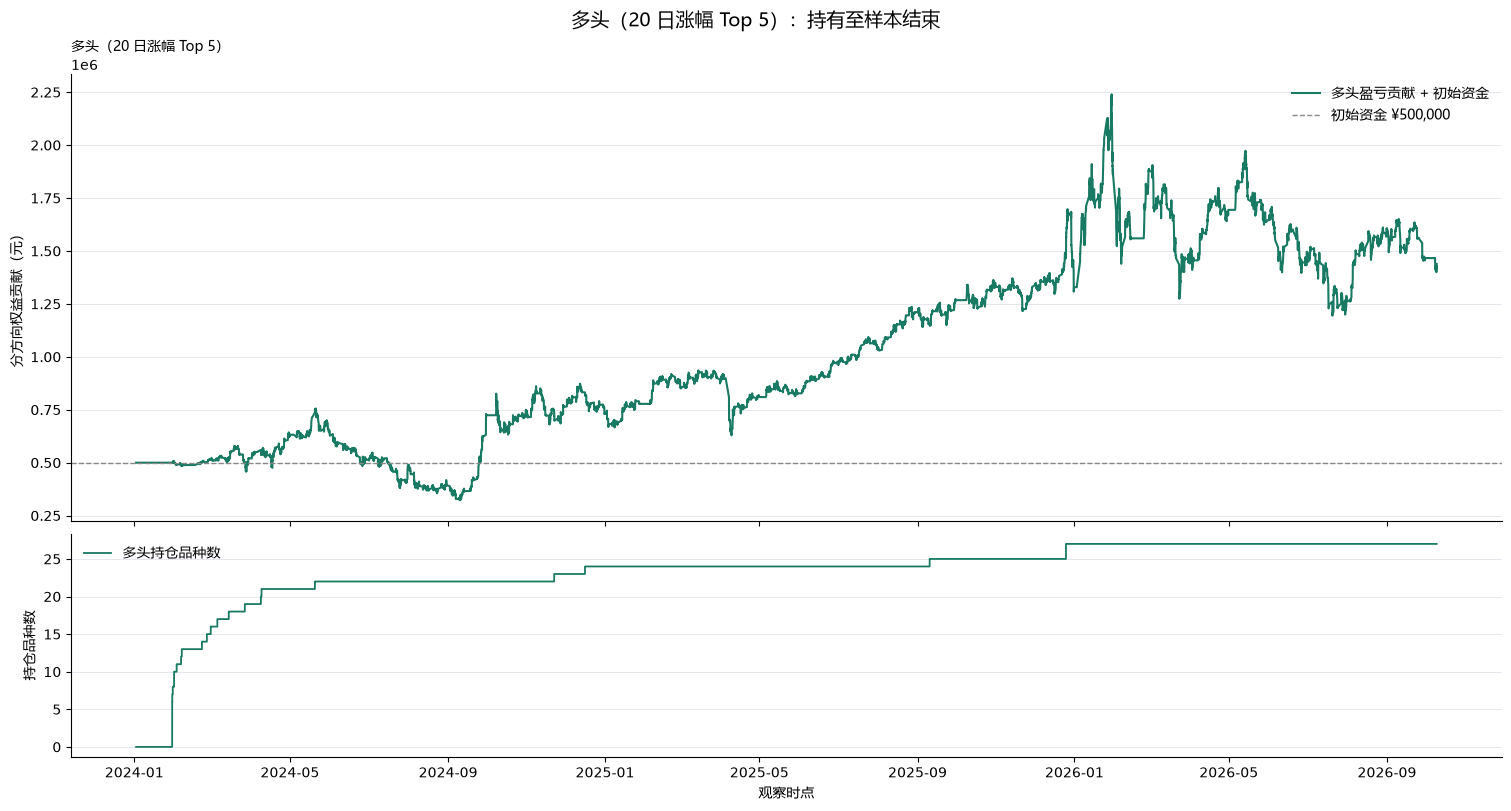

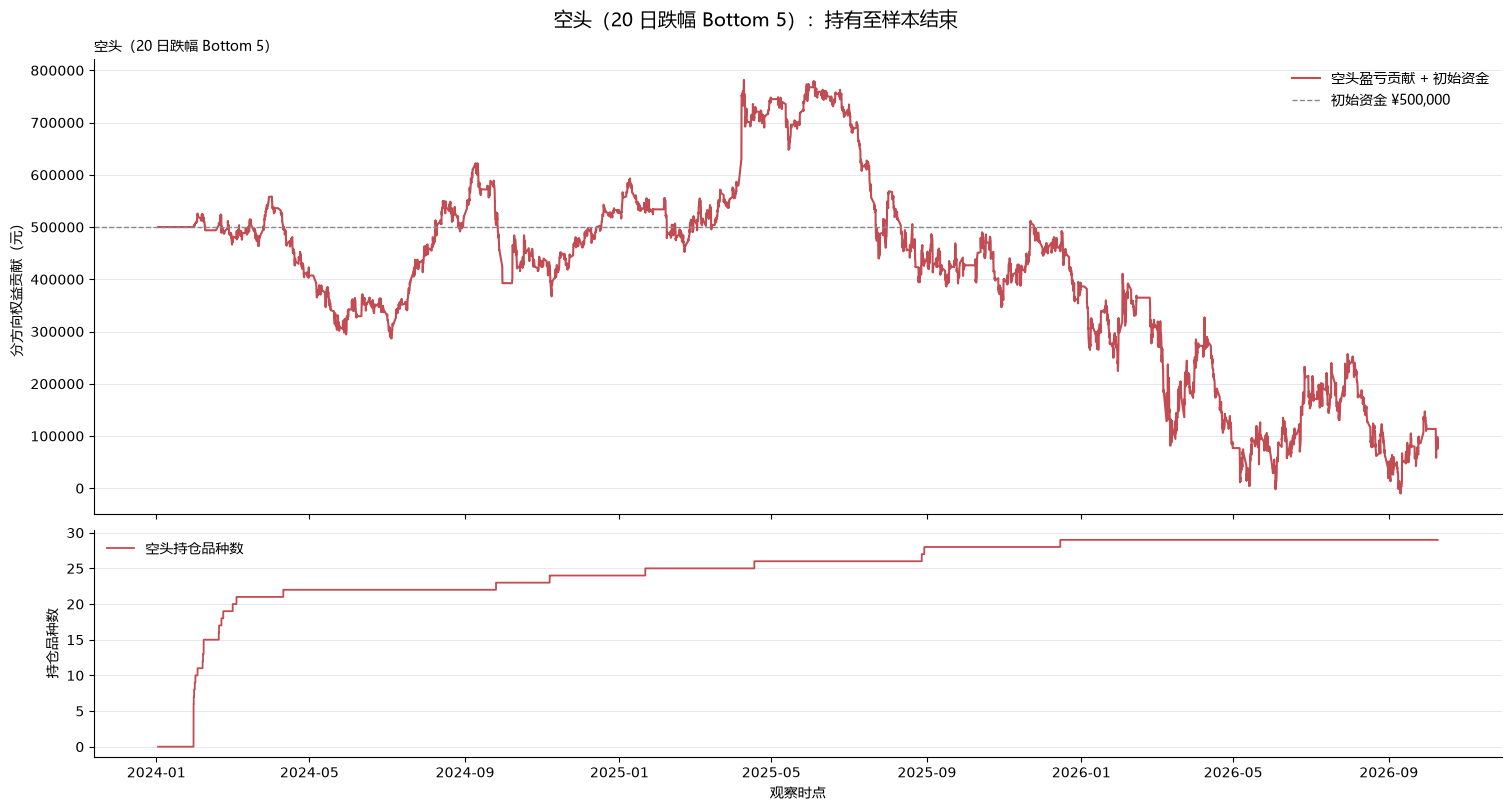

In [6]:
times = [point["timestamp"] for point in curve]
long_pnl = [point["long_pnl"] for point in curve]
short_pnl = [point["short_pnl"] for point in curve]
long_count = [point["long_positions"] for point in curve]
short_count = [point["short_positions"] for point in curve]
font = FontProperties(fname=r"C:\Windows\Fonts\msyh.ttc")

# 分方向绘图：每张图只展示对应方向的盈亏贡献与持仓数。
for side, pnl_values, count_values, color, label, filename in [
    ("多头（20 日涨幅 Top 5）", long_pnl, long_count, "#187a63", "多头", "evergreen_long_equity.png"),
    ("空头（20 日跌幅 Bottom 5）", short_pnl, short_count, "#c34b52", "空头", "evergreen_short_equity.png"),
]:
    fig, (ax_equity, ax_count) = plt.subplots(2, 1, figsize=(15, 8), sharex=True,
                                              constrained_layout=True,
                                              gridspec_kw={"height_ratios": [2, 1]})
    side_equity = [INITIAL_CAPITAL + value for value in pnl_values]
    ax_equity.plot(times, side_equity, color=color, linewidth=1.5,
                   label=f"{label}盈亏贡献 + 初始资金")
    ax_equity.axhline(INITIAL_CAPITAL, color="#888", linestyle="--", linewidth=1,
                      label="初始资金 ¥500,000")
    ax_equity.set_ylabel("分方向权益贡献（元）", fontproperties=font)
    ax_equity.set_title(side, loc="left", fontproperties=font)
    ax_equity.legend(frameon=False, prop=font)
    ax_equity.grid(axis="y", color="#e5e9ef", linewidth=0.7)
    ax_count.step(times, count_values, where="post", color=color, linewidth=1.3,
                  label=f"{label}持仓品种数")
    ax_count.set_ylabel("持仓品种数", fontproperties=font)
    ax_count.set_xlabel("观察时点", fontproperties=font)
    ax_count.legend(frameon=False, prop=font)
    ax_count.grid(axis="y", color="#e5e9ef", linewidth=0.7)
    for ax in (ax_equity, ax_count):
        ax.spines[["top", "right"]].set_visible(False)
    ax_count.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=6, maxticks=10))
    ax_count.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    fig.suptitle(f"{side}：持有至样本结束", fontproperties=font, fontsize=14)
    fig.savefig(OUTPUT_DIR / filename, dpi=170, bbox_inches="tight")
    plt.show()


## 4. 多头、空头持仓时间轴和指定时点持仓

涨幅榜做多、跌幅榜做空各导出一张持仓图。绿色图只看多头品种，红色图只看空头品种；持仓条表示首次入场至样本结束。可修改 `HOLDINGS_AT` 查询任意时点最近一条快照。

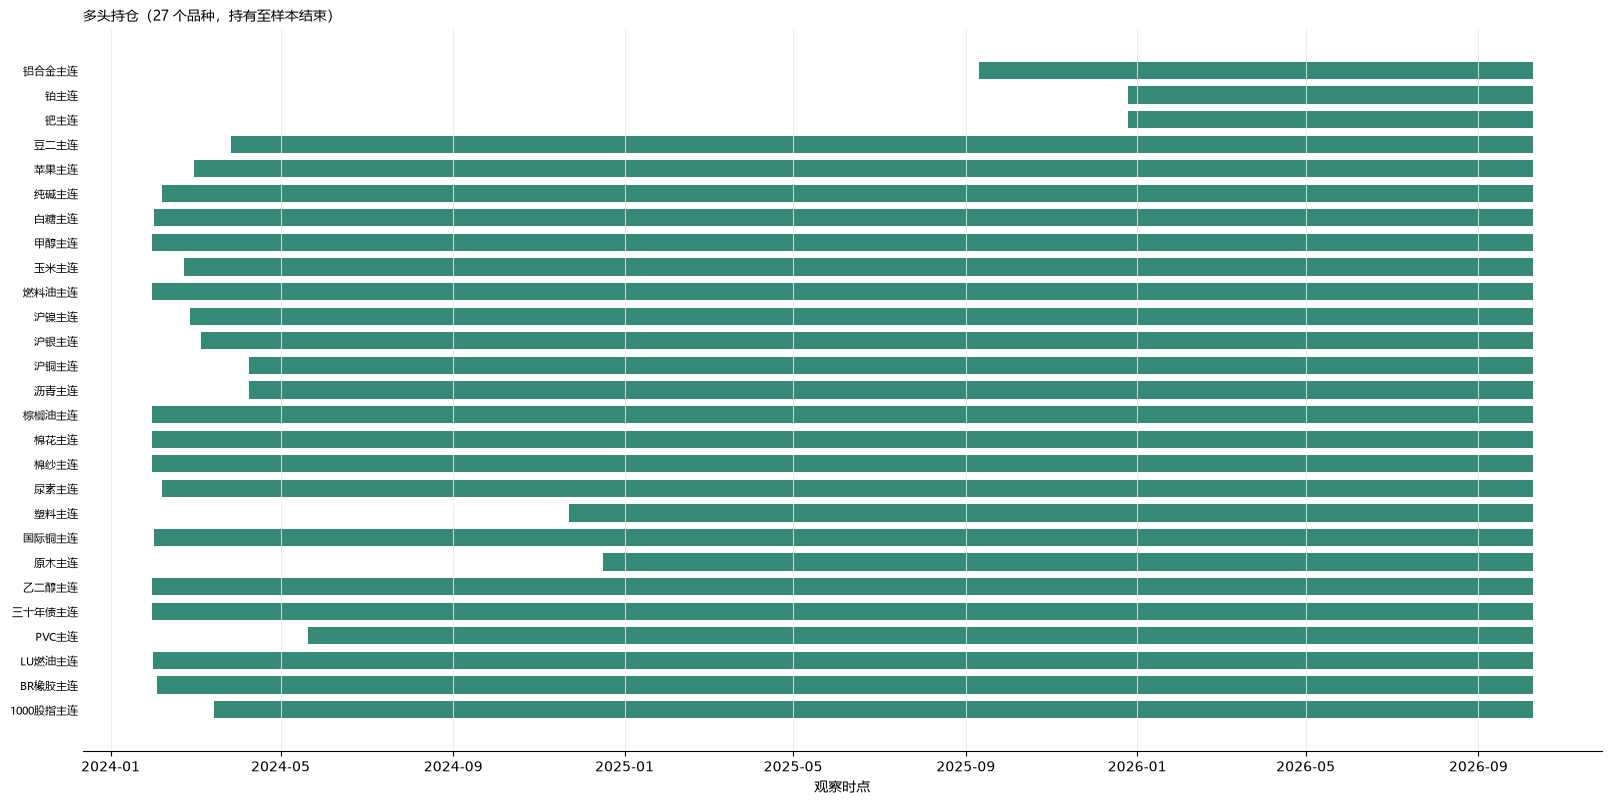

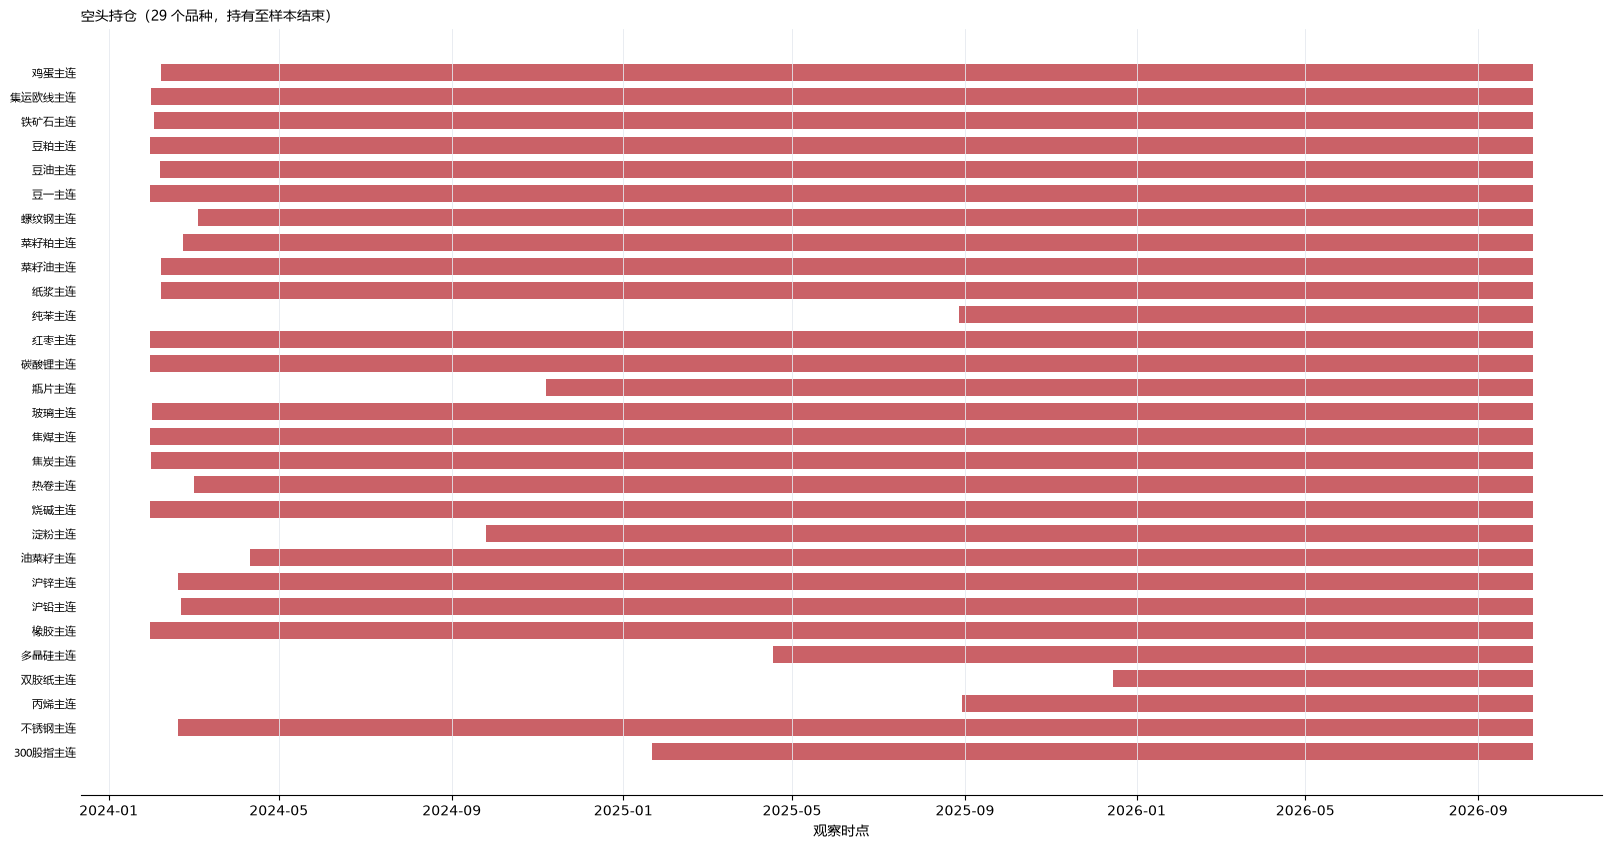

指定时点 2026-10-08 15:00:00；实际采用快照 2026-10-08 15:00:00；持仓 56 个品种。


,side,instrument,contract,signal_time,entry_time,entry_price,mark_price,floating_pnl,entry_margin,rank_return
0,多头,1000股指主连,IM2612,2024-03-14 09:30:00,2024-03-14 10:30:00,"5,504.40","7,022.20","¥705,800","¥115,646",—
2,多头,BR橡胶主连,br2611,2024-02-02 21:00:00,2024-02-02 22:00:00,"12,490.00","16,590.00","¥26,600","¥7,674",—
3,多头,LU燃油主连,lu2611,2024-01-30 21:00:00,2024-01-30 22:00:00,"4,400.00","5,975.00","¥30,060","¥6,723",—
4,多头,PVC主连,v2701,2024-05-20 09:00:00,2024-05-20 10:00:00,"6,338.00","4,915.00","¥-13,970","¥2,090",0.18%
5,多头,三十年债主连,TL2612,2024-01-30 11:15:00,2024-01-30 13:00:00,104.46,116.86,"¥132,200","¥35,581",0.82%
8,多头,乙二醇主连,eg2611,2024-01-30 09:00:00,2024-01-30 10:00:00,"4,726.00","5,419.00","¥12,300","¥4,040",—
9,多头,原木主连,lg2611,2024-12-16 09:00:00,2024-12-16 10:00:00,804.50,832.00,"¥-2,655","¥4,142",-0.42%
11,多头,国际铜主连,bc2611,2024-01-31 21:00:00,2024-01-31 22:00:00,"62,280.00","98,540.00","¥179,700","¥33,698",—
12,多头,塑料主连,l2701,2024-11-22 10:00:00,2024-11-22 11:15:00,"8,488.00","8,697.00","¥5,565","¥2,842",5.05%
14,多头,尿素主连,UR2701,2024-02-05 14:15:00,2024-02-06 09:00:00,"2,143.00","1,768.00","¥-4,900","¥3,346",-0.23%


In [7]:
HOLDINGS_AT = "2026-10-08 15:00:00"
positions = RESULT["positions"]
side_colors = {"多头": "#187a63", "空头": "#c34b52"}

for side, filename in [("多头", "evergreen_long_holdings.png"),
                       ("空头", "evergreen_short_holdings.png")]:
    side_rows = [row for row in positions if row["side"] == side]
    names = sorted({row["instrument"] for row in side_rows})
    fig_height = max(5, min(18, 2 + len(names) * 0.22))
    fig, ax = plt.subplots(figsize=(16, fig_height), constrained_layout=True)
    y = {name: i for i, name in enumerate(names)}
    ranges = defaultdict(list)
    for row in side_rows:
        ranges[row["instrument"]].append(row["timestamp"])
    for name, stamps in ranges.items():
        start, end = min(stamps), max(stamps)
        left = mdates.date2num(start)
        right = mdates.date2num(end if end > start else end + pd.Timedelta(minutes=1))
        ax.broken_barh([(left, max(right-left, 1/1440))], (y[name]-0.35, 0.7),
                       facecolors=side_colors[side], alpha=0.88)
    ax.set_yticks(range(len(names)))
    ax.set_yticklabels(names, fontproperties=font, fontsize=8)
    ax.set_title(f"{side}持仓（{len(names)} 个品种，持有至样本结束）",
                 loc="left", fontproperties=font)
    ax.grid(axis="x", color="#e5e9ef", linewidth=0.6)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=6, maxticks=10))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.set_xlabel("观察时点", fontproperties=font)
    fig.savefig(OUTPUT_DIR / filename, dpi=170, bbox_inches="tight")
    plt.show()

requested = datetime.fromisoformat(HOLDINGS_AT)
eligible = [row for row in positions if row["timestamp"] <= requested]
if not eligible:
    print("所选时点前没有持仓。")
else:
    snapshot_time = max(row["timestamp"] for row in eligible)
    current = [row for row in eligible if row["timestamp"] == snapshot_time]
    holdings_frame = pd.DataFrame(current).sort_values(["side", "instrument"])
    print(f"指定时点 {HOLDINGS_AT}；实际采用快照 {snapshot_time:%Y-%m-%d %H:%M:%S}；持仓 {len(current)} 个品种。")
    display(holdings_frame[["side", "instrument", "contract", "signal_time", "entry_time", "entry_price", "mark_price", "floating_pnl", "entry_margin", "rank_return"]].style.format({
        "entry_price": "{:,.2f}", "mark_price": "{:,.2f}", "floating_pnl": "¥{:,.0f}",
        "entry_margin": "¥{:,.0f}", "rank_return": "{:.2%}",
    }, na_rep="—"))

## 5. 导出汇总、权益、交易和持仓快照

导出文件写入 `backtest_output/20day_evergreen_hold/`，不会覆盖现有四组榜单策略结果。多头、空头的收益曲线和持仓时间轴分别导出独立 PNG。

In [8]:
def write_rows(path, rows):
    path.parent.mkdir(parents=True, exist_ok=True)
    if not rows:
        return
    with path.open("w", encoding="utf-8-sig", newline="") as handle:
        writer = DictWriter(handle, fieldnames=list(rows[0]), extrasaction="ignore")
        writer.writeheader()
        for row in rows:
            writer.writerow({key: value.isoformat(sep=" ") if isinstance(value, datetime) else value
                             for key, value in row.items()})

write_rows(OUTPUT_DIR / "summary.csv", [summary])
write_rows(OUTPUT_DIR / "equity_curve.csv", curve)
write_rows(OUTPUT_DIR / "trades.csv", trades)
write_rows(OUTPUT_DIR / "positions.csv", positions)
write_rows(OUTPUT_DIR / "rejected_entries.csv", RESULT["rejected"])
print("结果目录：", OUTPUT_DIR)
print("已导出权益曲线、逐笔持仓/结算记录、时点持仓快照和未成交入场记录。")

结果目录： d:\HuaweiMoveData\Users\32874\Desktop\Futures Ranking\Futures_Ranking\backtest_output\20day_evergreen_hold
已导出权益曲线、逐笔持仓/结算记录、时点持仓快照和未成交入场记录。
